# Parte 1 — Equipe, dataset e arquitetura Inception-v4

**Projeto de CNN · Machine Learning e Deep Learning (CC6NA 2026.2) · Profa. Polyana Santos Fonseca Nascimento**
**Transfer learning e fine-tuning em redes neurais convolucionais**

| | |
|---|---|
| Equipe | **Inception** (vaga 1 da planilha) |
| Integrantes | Alberto Acosta · Davi Corrêa · Gabriel Albuquerque |
| Arquitetura | **Inception-v4** (Szegedy, Ioffe, Vanhoucke & Alemi, AAAI 2017) |
| Implementação | PyTorch + `timm` (`inception_v4.tf_in1k`, pesos ImageNet-1k) |
| Dataset | Sea Animals Image Dataset 🌊 (Kaggle) |

Este notebook cobre a **etapa 1 da lauda** (equipe, arquitetura e dataset). Os demais:

| Notebook | Etapas da lauda |
|---|---|
| `01_equipe_dataset_arquitetura.ipynb` (este) | 1 — integrantes, dataset, pesquisa da arquitetura |
| `02_dados_e_base_congelada.ipynb` | 2 e 3 — análise e pré-processamento dos dados, base congelada |
| `03_fine_tuning_planejamento.ipynb` | 4 — planejamento e execução das estratégias de fine-tuning A e B |

Na entrega final os três são unidos em um notebook único, executado em ordem e com as saídas salvas.

## 1. Dataset e justificativa

**Sea Animals Image Dataset 🌊** — Kaggle, `vencerlanz09/sea-animals-image-dataste`
<https://www.kaggle.com/datasets/vencerlanz09/sea-animals-image-dataste>

Cerca de **13,7 mil fotos** de animais marinhos, uma pasta por classe (o rótulo é o nome da pasta). A versão original tem **23 pastas**:
Clams, Corals, Crabs, Dolphin, Eel, Fish, Jelly Fish, Lobster, Nudibranchs, Octopus, Otter, Penguin, Puffers, Sea Rays, Sea Urchins, Seahorse, Seal, Sharks, Shrimp, Squid, Starfish, Turtle_Tortoise, Whale.
*(A contagem exata por classe e a lista final usada estão nas seções 2.2 e 2.4 do notebook 02.)*

### Problema

- **Tarefa:** classificação multiclasse de imagens (uma classe por imagem).
- **Target:** o **tipo de animal marinho** (a pasta da imagem).
- **Finalidade possível:** catalogação automática de fotos de mergulho e apoio a levantamentos de biodiversidade marinha, onde um especialista precisaria rotular milhares de fotos à mão.
- **Sobre o "foco em caranguejos" da planilha:** o dataset tem **uma única** classe *Crabs* e não separa espécies, então não é possível classificar espécies de caranguejo. O target é o tipo de animal; o foco em caranguejos entra como **acompanhamento específico da classe Crabs** na análise de erros (precisão, recall e com quem ela se confunde, principalmente Lobster e Shrimp — notebook 02, seção 3.3).

### Por que este dataset

| Critério | Situação |
|---|---|
| Exigência da lauda (≥ 1.000 imagens e ≥ 100 por classe) | Atendida com folga (~13,7 mil imagens; verificado no notebook 02) |
| Repositório confiável e público | Kaggle, com uma pasta por classe |
| Desafio real para transfer learning | Imagens de fontes variadas (subaquáticas, aquário, fora d'água), tamanhos e proporções diferentes, fundos dominantes (água azul) |
| Classes parecidas entre si | Crabs × Lobster × Shrimp; Seal × Otter; Sharks × Dolphin × Whale; Squid × Octopus. Bom para analisar erros e para justificar o fine-tuning |
| Relação com o ImageNet | O ImageNet tem várias dessas categorias (tubarão, arraia, água-viva, lagosta…), então os pesos pré-treinados devem transferir bem — mas **não** tem todas (ex.: nudibrânquio, coral como classe), o que deixa espaço para o fine-tuning ajudar |

**Limitações já previstas** (discutidas no notebook 02): a classe **Fish** é genérica — tubarões, baiacus, enguias e cavalos-marinhos também são peixes, então há sobreposição de conceito com Sharks, Puffers, Eel e Seahorse; a classe **Turtle_Tortoise** mistura tartarugas marinhas com jabutis terrestres; o dataset pode ter duplicatas e rótulos errados, que verificamos na seção 2.4 do notebook 02.

## 2. Arquitetura: Inception-v4

| | |
|---|---|
| Nome | **Inception-v4** |
| Autores | Christian Szegedy, Sergey Ioffe, Vincent Vanhoucke, Alexander A. Alemi (Google) |
| Artigo | *Inception-v4, Inception-ResNet and the Impact of Residual Connections on Learning* |
| Publicação | arXiv 1602.07261 (fev/2016); **AAAI 2017** (DOI 10.1609/aaai.v31i1.11231) |
| Entrada | 299×299×3 |
| Parâmetros | ≈ 42,7 milhões (com o classificador de 1000 classes do ImageNet) |
| ImageNet (artigo, 1 recorte, 1 modelo) | erro top-1 **20,0%**, top-5 **5,0%** |

### 2.1 Linha do tempo da família Inception

| Versão | Artigo | O que trouxe |
|---|---|---|
| Inception-v1 (GoogLeNet) | Szegedy et al., CVPR 2015 | O **módulo Inception**: convoluções 1×1, 3×3, 5×5 e pooling **em paralelo**, concatenadas; 1×1 para reduzir canais; venceu o ILSVRC 2014 |
| Inception-v2 (BN-Inception) | Ioffe & Szegedy, ICML 2015 | **Batch Normalization** em toda a rede |
| Inception-v3 | Szegedy et al., CVPR 2016 | **Fatoração** de convoluções (5×5 → duas 3×3; n×n → 1×n + n×1), redução de grade eficiente, entrada 299×299 |
| **Inception-v4** | Szegedy et al., AAAI 2017 | Arquitetura **mais uniforme e simplificada**, mais módulos Inception, stem reformulado, módulos de redução dedicados |
| Inception-ResNet-v1/v2 | mesmo artigo da v4 | Inception + **conexões residuais** |

### 2.2 Diagrama e explicação dos blocos

O diagrama abaixo foi desenhado pela equipe a partir das figuras 3 a 9 do artigo. Embaixo de cada bloco está o índice correspondente em `model.features` na implementação do `timm`, que é como o código das partes 2 e 3 se refere a eles.

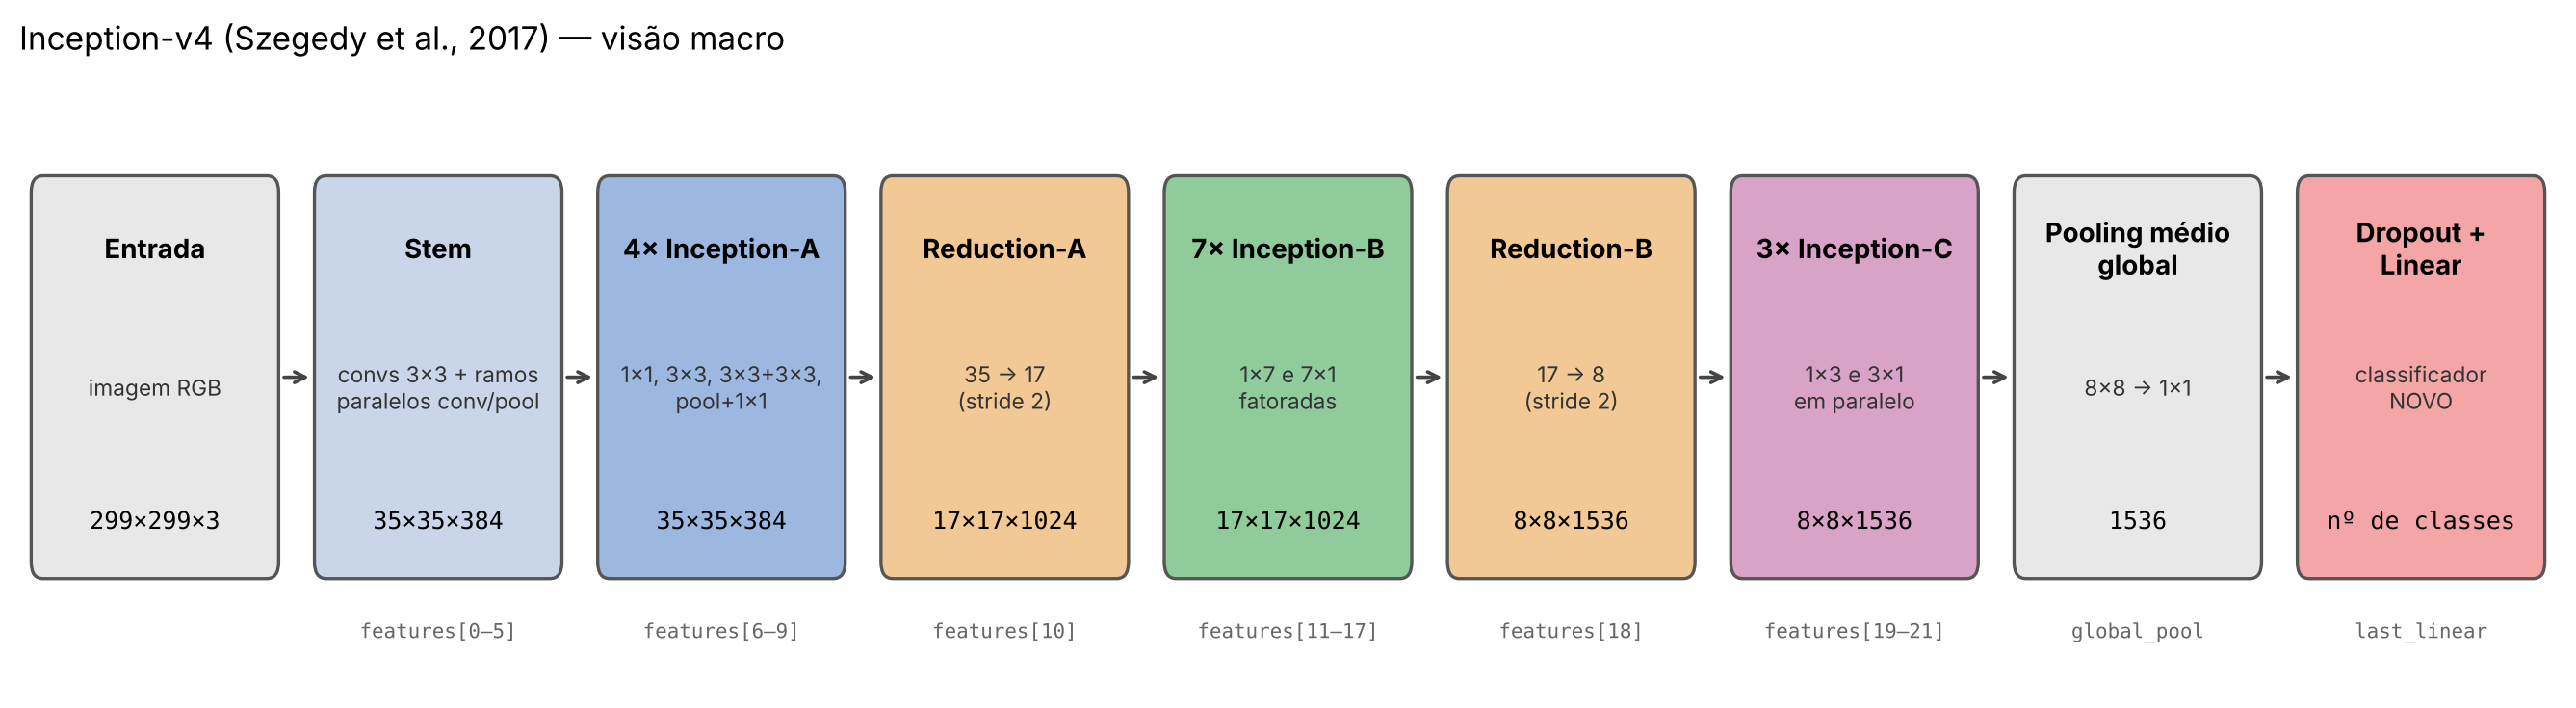

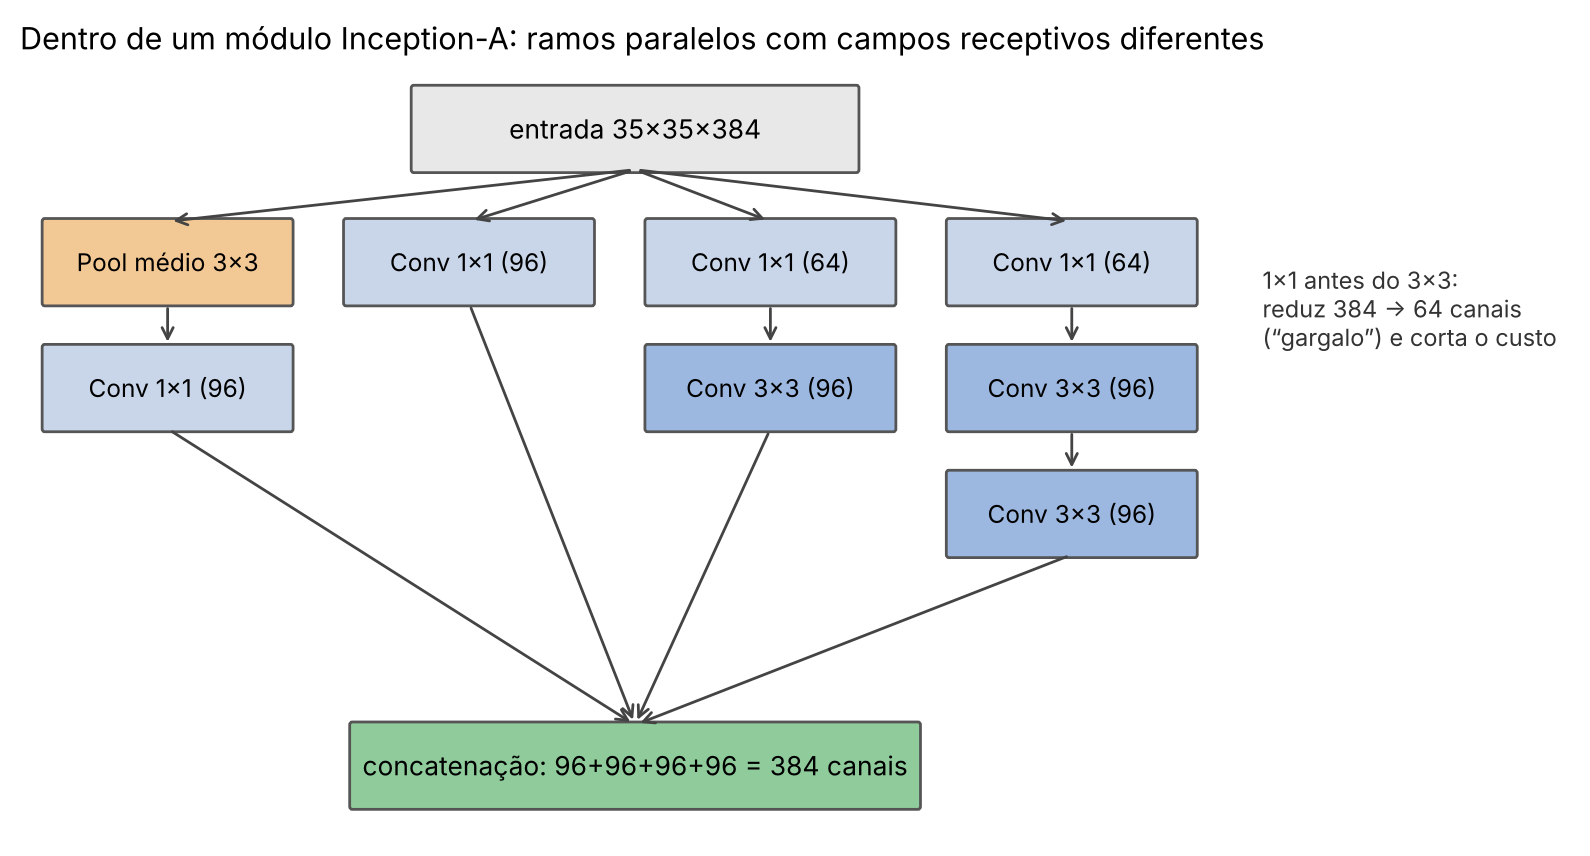

In [1]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# (rótulo, detalhe, saída, índices em model.features do timm, cor)
BLOCOS_V4 = [
    ("Entrada", "imagem RGB", "299×299×3", None, "#E8E8E8"),
    ("Stem", "convs 3×3 + ramos\nparalelos conv/pool", "35×35×384", "0–5", "#C9D6EA"),
    ("4× Inception-A", "1×1, 3×3, 3×3+3×3,\npool+1×1", "35×35×384", "6–9", "#9DB8E0"),
    ("Reduction-A", "35 → 17\n(stride 2)", "17×17×1024", "10", "#F2C894"),
    ("7× Inception-B", "1×7 e 7×1\nfatoradas", "17×17×1024", "11–17", "#8FCB9B"),
    ("Reduction-B", "17 → 8\n(stride 2)", "8×8×1536", "18", "#F2C894"),
    ("3× Inception-C", "1×3 e 3×1\nem paralelo", "8×8×1536", "19–21", "#D9A3C7"),
    ("Pooling médio\nglobal", "8×8 → 1×1", "1536", "global_pool", "#E8E8E8"),
    ("Dropout +\nLinear", "classificador\nNOVO", "nº de classes", "last_linear", "#F4A6A6"),
]


def desenhar_inception_v4(destaque=None, titulo="Inception-v4 (Szegedy et al., 2017) — visão macro", ax=None):
    """Desenha a arquitetura bloco a bloco.

    destaque: dict {índice_do_bloco_na_lista: rótulo} para marcar blocos treináveis (usado na parte 3).
    """
    destaque = destaque or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(17, 4.2))
    w, h, gap = 1.62, 1.9, 0.28
    for i, (nome, det, saida, idx, cor) in enumerate(BLOCOS_V4):
        x = i * (w + gap)
        borda = "#C0392B" if i in destaque else "#555555"
        ax.add_patch(FancyBboxPatch((x, 0), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    fc=cor, ec=borda, lw=3 if i in destaque else 1.2))
        ax.text(x + w / 2, h - 0.33, nome, ha="center", va="center", fontsize=10, fontweight="bold")
        ax.text(x + w / 2, h / 2 - 0.05, det, ha="center", va="center", fontsize=8.2, color="#333333")
        ax.text(x + w / 2, 0.25, saida, ha="center", va="center", fontsize=9, family="monospace")
        if idx:
            ax.text(x + w / 2, -0.28, f"features[{idx}]" if idx[0].isdigit() else idx,
                    ha="center", va="center", fontsize=7.5, color="#666666", family="monospace")
        if i in destaque:
            ax.text(x + w / 2, h + 0.25, destaque[i], ha="center", va="center", fontsize=8.5,
                    color="#C0392B", fontweight="bold")
        if i < len(BLOCOS_V4) - 1:
            ax.annotate("", xy=(x + w + gap - 0.02, h / 2), xytext=(x + w + 0.02, h / 2),
                        arrowprops=dict(arrowstyle="->", lw=1.3, color="#444444"))
    total_w = len(BLOCOS_V4) * (w + gap) - gap
    ax.set_xlim(-0.1, total_w + 0.1); ax.set_ylim(-0.55, h + 0.55)
    ax.axis("off")
    ax.set_title(titulo, fontsize=12, loc="left")
    return ax


def desenhar_modulo_inception_a(ax=None):
    """Um módulo Inception-A por dentro: 4 ramos em paralelo, concatenados nos canais."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    ramos = [
        ["Pool médio 3×3", "Conv 1×1 (96)"],
        ["Conv 1×1 (96)"],
        ["Conv 1×1 (64)", "Conv 3×3 (96)"],
        ["Conv 1×1 (64)", "Conv 3×3 (96)", "Conv 3×3 (96)"],
    ]
    bw, bh = 2.0, 0.55
    ax.add_patch(FancyBboxPatch((3.2, 4.3), 3.6, 0.55, boxstyle="round,pad=0.02", fc="#E8E8E8", ec="#555555"))
    ax.text(5.0, 4.575, "entrada 35×35×384", ha="center", va="center", fontsize=9.5)
    for r, camadas in enumerate(ramos):
        x = 0.2 + r * 2.45
        for k, nome in enumerate(camadas):
            y = 3.4 - k * 0.85
            cor = "#F2C894" if "Pool" in nome else ("#C9D6EA" if "1×1" in nome else "#9DB8E0")
            ax.add_patch(FancyBboxPatch((x, y), bw, bh, boxstyle="round,pad=0.02", fc=cor, ec="#555555"))
            ax.text(x + bw / 2, y + bh / 2, nome, ha="center", va="center", fontsize=8.8)
            if k == 0:
                ax.annotate("", xy=(x + bw / 2, y + bh), xytext=(5.0, 4.3),
                            arrowprops=dict(arrowstyle="->", lw=1, color="#444444"))
            else:
                ax.annotate("", xy=(x + bw / 2, y + bh), xytext=(x + bw / 2, y + 0.85),
                            arrowprops=dict(arrowstyle="->", lw=1, color="#444444"))
        y_fim = 3.4 - (len(camadas) - 1) * 0.85
        ax.annotate("", xy=(5.0, 0.55), xytext=(x + bw / 2, y_fim),
                    arrowprops=dict(arrowstyle="->", lw=1, color="#444444"))
    ax.add_patch(FancyBboxPatch((2.7, 0.0), 4.6, 0.55, boxstyle="round,pad=0.02", fc="#8FCB9B", ec="#555555"))
    ax.text(5.0, 0.275, "concatenação: 96+96+96+96 = 384 canais", ha="center", va="center", fontsize=9.5)
    ax.text(10.1, 3.65, "1×1 antes do 3×3:\nreduz 384 → 64 canais\n(“gargalo”) e corta o custo", fontsize=8.5,
            color="#333333", va="top")
    ax.set_xlim(0, 12.6); ax.set_ylim(-0.2, 5.0); ax.axis("off")
    ax.set_title("Dentro de um módulo Inception-A: ramos paralelos com campos receptivos diferentes", fontsize=11,
                 loc="left")
    return ax


desenhar_inception_v4()
plt.show()
desenhar_modulo_inception_a()
plt.show()

| Bloco | Saída | O que faz |
|---|---|---|
| **Stem** | 35×35×384 | Reduz a imagem de 299 para 35 px de lado antes dos módulos Inception. Diferente das CNNs convencionais, que só empilham conv + pool, o stem da v4 já tem **ramos paralelos** (conv com stride 2 ao lado de max-pool, concatenados), para reduzir a resolução sem perder informação. Usa convoluções *valid* (sem padding), por isso 299 → 149 → 147 → 73 → 71 → 35 |
| **Inception-A** (×4) | 35×35×384 | Quatro ramos em paralelo: 1×1; 1×1 → 3×3; 1×1 → 3×3 → 3×3 (equivale a um 5×5 fatorado); pool médio → 1×1. Cada ramo enxerga um **campo receptivo diferente**, e a rede aprende a combinar as escalas. Bordas e texturas simples |
| **Reduction-A** | 17×17×1024 | Reduz a grade de 35 para 17 com três ramos paralelos (max-pool, conv 3×3 stride 2 e 1×1 → 3×3 → 3×3 stride 2) e **aumenta os canais** (384 → 1024). Reduzir em paralelo evita o "gargalo representacional" de simplesmente aplicar pooling |
| **Inception-B** (×7) | 17×17×1024 | O núcleo da rede (sete blocos, ~20 M de parâmetros). Usa convoluções **assimétricas 1×7 e 7×1** no lugar de 7×7: mesmo campo receptivo com bem menos parâmetros. Padrões de nível médio: partes de objetos, formas, texturas como escamas e carapaças |
| **Reduction-B** | 8×8×1536 | Segunda redução de grade (17 → 8), também em ramos paralelos, aumentando os canais para 1536 |
| **Inception-C** (×3) | 8×8×1536 | Ramos com 1×3 e 3×1 **em paralelo** (expansão dos filtros), para gerar representações de alta dimensão na grade pequena. São as features mais abstratas e mais ligadas às 1000 classes do ImageNet |
| **Pool médio global** | 1536 | Média de cada canal sobre a grade 8×8. Substitui as camadas densas gigantes das CNNs antigas (na VGG elas concentram a maior parte dos parâmetros) |
| **Dropout + Linear** | nº de classes | No artigo: dropout (mantém 80%) + softmax de 1000 classes. **No nosso trabalho este é o classificador trocado**: dropout 0,3 + linear 1536 → nº de classes |

### 2.3 Conferência no código: formatos de saída e parâmetros por bloco

Montamos a rede do `timm` **só com a estrutura** (`pretrained=False`, sem baixar pesos) e passamos um tensor de zeros pelos blocos, para conferir que a implementação bate com o artigo.

In [2]:
# No Colab, torch já vem instalado; timm às vezes não.
%pip install -q timm

In [3]:
import pandas as pd
import torch
import timm

modelo = timm.create_model("inception_v4.tf_in1k", pretrained=False).eval()

linhas, x = [], torch.zeros(1, 3, 299, 299)
with torch.no_grad():
    for i, bloco in enumerate(modelo.features):
        x = bloco(x)
        linhas.append((i, type(bloco).__name__, "×".join(map(str, x.shape[2:])) + f"×{x.shape[1]}",
                       sum(p.numel() for p in bloco.parameters())))
tabela = pd.DataFrame(linhas, columns=["features[i]", "bloco (timm)", "saída (A×L×C)", "parâmetros"])

total = sum(p.numel() for p in modelo.parameters())
print(f"timm {timm.__version__} | parâmetros totais (classificador ImageNet de 1000 classes): {total:,}")
print("Classificador original:", modelo.get_classifier())
tabela

timm 1.0.31 | parâmetros totais (classificador ImageNet de 1000 classes): 42,679,816
Classificador original: Linear(in_features=1536, out_features=1000, bias=True)


,features[i],bloco (timm),saída (A×L×C),parâmetros
0,0,ConvNormAct,149×149×32,928
1,1,ConvNormAct,147×147×32,9280
2,2,ConvNormAct,147×147×64,18560
3,3,Mixed3a,73×73×160,55488
4,4,Mixed4a,71×71×192,189312
5,5,Mixed5a,35×35×384,332160
6,6,InceptionA,35×35×384,317632
7,7,InceptionA,35×35×384,317632
8,8,InceptionA,35×35×384,317632
9,9,InceptionA,35×35×384,317632


In [4]:
# Onde estão os parâmetros: soma por grupo de blocos
grupos = {"Stem (0–5)": range(0, 6), "Inception-A ×4 (6–9)": range(6, 10), "Reduction-A (10)": [10],
          "Inception-B ×7 (11–17)": range(11, 18), "Reduction-B (18)": [18], "Inception-C ×3 (19–21)": range(19, 22)}
por_grupo = {g: sum(tabela.loc[list(idx), "parâmetros"]) for g, idx in grupos.items()}
por_grupo["Classificador ImageNet (last_linear)"] = sum(p.numel() for p in modelo.get_classifier().parameters())
por_grupo = pd.Series(por_grupo, name="parâmetros").to_frame()
por_grupo["% do total"] = (100 * por_grupo["parâmetros"] / total).round(1)
por_grupo

,parâmetros,% do total
Stem (0–5),605728,1.4
Inception-A ×4 (6–9),1270528,3.0
Reduction-A (10),2306112,5.4
Inception-B ×7 (11–17),20553792,48.2
Reduction-B (18),2747392,6.4
Inception-C ×3 (19–21),13659264,32.0
Classificador ImageNet (last_linear),1537000,3.6


Leitura da tabela: os formatos batem com o artigo (stem 35×35×384, Reduction-A 17×17×1024, Reduction-B 8×8×1536). Quase metade dos parâmetros está nos **7 blocos Inception-B** e o classificador do ImageNet sozinho tem ~1,5 M. Isso orienta o fine-tuning (notebook 03): descongelar só o topo (Reduction-B + Inception-C) mexe em ~40% da rede; descer até os Inception-B mexe em quase 90%.

### 2.4 Principal inovação em relação a uma CNN convencional

Uma CNN convencional (LeNet, AlexNet, VGG) é uma **pilha linear**: em cada camada o projetista escolhe *um* tamanho de filtro, e o custo cresce rápido ao aumentar profundidade e largura. A ideia central da família Inception é outra:

1. **Convoluções em paralelo com tamanhos diferentes, concatenadas.** O mesmo bloco olha a imagem em várias escalas (1×1, 3×3, "5×5", pooling) e a própria rede aprende quanto usar de cada uma. Útil aqui: o mesmo animal aparece pequeno no fundo ou ocupando a foto inteira.
2. **Convoluções 1×1 como gargalo.** Antes de um filtro caro, uma 1×1 reduz o número de canais (ex.: 384 → 64). Deixa a rede larga e profunda com custo controlado.
3. **Fatoração de convoluções.** 5×5 vira duas 3×3; n×n vira 1×n seguida de n×1. Mesmo campo receptivo, menos parâmetros e mais não-linearidades.
4. **Pooling médio global no lugar de camadas densas grandes**, o que corta parâmetros e reduz overfitting.
5. **Redução de grade em ramos paralelos** (Reduction-A/B), em vez de só pooling, para não perder informação ao diminuir a resolução.

A célula abaixo mede o efeito dos itens 2 e 3 com camadas reais do PyTorch e compara o tamanho da Inception-v4 com a VGG-16.

In [5]:
import torch.nn as nn

def n_params(*camadas):
    return sum(p.numel() for c in camadas for p in c.parameters())

# (2) gargalo 1x1: ramo 1x1(384->64) + 3x3(64->96) do Inception-A  vs  3x3 direto 384->96
direto = n_params(nn.Conv2d(384, 96, 3, bias=False))
gargalo = n_params(nn.Conv2d(384, 64, 1, bias=False), nn.Conv2d(64, 96, 3, bias=False))
# (3a) 5x5 vs duas 3x3 (96 canais)
c5 = n_params(nn.Conv2d(96, 96, 5, bias=False))
c33 = n_params(nn.Conv2d(96, 96, 3, bias=False), nn.Conv2d(96, 96, 3, bias=False))
# (3b) 7x7 vs 1x7 + 7x1 (192 -> 224 canais, como no Inception-B)
c7 = n_params(nn.Conv2d(192, 224, 7, bias=False))
c17 = n_params(nn.Conv2d(192, 224, (1, 7), bias=False), nn.Conv2d(224, 224, (7, 1), bias=False))

comparacao = pd.DataFrame([
    ("3×3 direto 384→96", direto, "1×1 384→64 + 3×3 64→96", gargalo),
    ("5×5 96→96", c5, "3×3 + 3×3", c33),
    ("7×7 192→224", c7, "1×7 + 7×1", c17),
], columns=["convencional", "parâmetros", "Inception", "parâmetros (Inception)"])
comparacao["economia"] = (1 - comparacao["parâmetros (Inception)"] / comparacao["parâmetros"]).map("{:.0%}".format)
display(comparacao)

vgg16 = timm.create_model("vgg16", pretrained=False)
print(f"VGG-16: {n_params(vgg16) / 1e6:.1f} M parâmetros | Inception-v4: {total / 1e6:.1f} M parâmetros")
del vgg16

,convencional,parâmetros,Inception,parâmetros (Inception),economia
0,3×3 direto 384→96,331776,1×1 384→64 + 3×3 64→96,79872,76%
1,5×5 96→96,230400,3×3 + 3×3,165888,28%
2,7×7 192→224,2107392,1×7 + 7×1,652288,69%


VGG-16: 138.4 M parâmetros | Inception-v4: 42.7 M parâmetros


### 2.5 Diferencial da v4 em relação à v3, e por que não a Inception-ResNet

**v4 × v3.** Segundo os autores, a v3 ainda carregava restrições das versões anteriores: o treinamento distribuído no DistBelief exigia particionar o modelo entre máquinas, e isso condicionou o desenho. Com a migração para o TensorFlow, essa restrição sumiu e eles redesenharam a rede de forma **mais simples e uniforme**:

| | Inception-v3 | Inception-v4 |
|---|---|---|
| Stem | Sequência de convs e poolings | Reformulado, **com ramos paralelos** (conv ‖ pool) e convs assimétricas 7×1/1×7 |
| Módulos | Escolhas diferentes ao longo da rede | **Uniformes por resolução**: o mesmo bloco A em 35×35, B em 17×17, C em 8×8 |
| Quantidade de módulos Inception | menor | **mais módulos** (4 A + 7 B + 3 C) |
| Redução de grade | blocos de redução da v3 | **Reduction-A e Reduction-B** definidos explicitamente |
| ImageNet (artigo, top-1 / top-5 de erro) | 21,2% / 5,6% | **20,0% / 5,0%** |

**Por que Inception-v4 e não Inception-ResNet-v2.** O mesmo artigo apresenta as Inception-ResNet, que somam conexões residuais (ideia da ResNet) aos módulos Inception. A conclusão dos autores: as conexões residuais **aceleram bastante o treinamento**, mas a acurácia final da v4 é praticamente a mesma da Inception-ResNet-v2 (20,0% × 19,9% de erro top-1). Escolhemos a v4 porque ela é a forma "pura" da ideia Inception, sem misturar com a família ResNet — o que deixa claro o que estamos estudando — e porque foi a versão validada na planilha.

**Por que PyTorch + timm.** O Keras não tem a Inception-v4 pronta (só a InceptionV3 e a InceptionResNetV2). O `timm` traz a v4 com os pesos ImageNet convertidos do TF-Slim oficial do Google (`inception_v4.tf_in1k`), junto com a configuração de pré-processamento original (299×299, pixels em [−1, 1]), usada no notebook 02.

## 3. Referências

1. SZEGEDY, C.; IOFFE, S.; VANHOUCKE, V.; ALEMI, A. A. Inception-v4, Inception-ResNet and the Impact of Residual Connections on Learning. In: **AAAI Conference on Artificial Intelligence**, 31., 2017. p. 4278–4284. DOI: 10.1609/aaai.v31i1.11231. Preprint: arXiv:1602.07261.
2. SZEGEDY, C. et al. Going Deeper with Convolutions. In: **IEEE CVPR**, 2015. (Inception-v1 / GoogLeNet). arXiv:1409.4842.
3. IOFFE, S.; SZEGEDY, C. Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift. In: **ICML**, 2015. arXiv:1502.03167.
4. SZEGEDY, C. et al. Rethinking the Inception Architecture for Computer Vision. In: **IEEE CVPR**, 2016. (Inception-v3). arXiv:1512.00567.
5. HE, K. et al. Deep Residual Learning for Image Recognition. In: **IEEE CVPR**, 2016. arXiv:1512.03385.
6. SIMONYAN, K.; ZISSERMAN, A. Very Deep Convolutional Networks for Large-Scale Image Recognition. In: **ICLR**, 2015. (VGG). arXiv:1409.1556.
7. WIGHTMAN, R. **PyTorch Image Models (timm)**. GitHub, 2019–. <https://github.com/huggingface/pytorch-image-models>. Modelo: <https://huggingface.co/timm/inception_v4.tf_in1k>.
8. VENCERLANZ09. **Sea Animals Image Dataset**. Kaggle. <https://www.kaggle.com/datasets/vencerlanz09/sea-animals-image-dataste>.